# Description

Step 4 of the plan on #733: in step 3 the logistic regression made money
before costs only in volatile markets. Is it tradable after costs if we
trade only then?

- Same model and trades as step 2: logistic regression on the sign of the
  move, walking forward by year, one trade every horizon
- Three rules for when to trade (`D21`):
  - `all`: every decision time (step 2)
  - `volatile`: only when the volatility regime of `D18` is volatile. This
    rule was chosen after looking at 2022-2026 in step 3, so it is an
    optimistic upper bound
  - `walk_forward`: in each year, trade a regime only if it made money
    after costs in the earlier years. Nothing here uses the future
- Always buying with the same rules, as a baseline
- One unit per trade, PnLs added, not compounded (`D22`)
- Horizons 1h, 4h, and 1d. At 5m and 15m the PnL per trade is under 0.6 bp
  before costs even in volatile markets (`tradability.targets.ipynb`)
- Costs from 0 to 20 bp per round trip, 10 bp by default

## Imports

In [1]:
%load_ext autoreload
%autoreload 2

import backtest_utils as butil
import data_utils as dutil
import matplotlib.pyplot as plt
import pandas as pd
import predict_utils as putil
import regime_utils as rutil

## Config

In [2]:
SYMBOLS = ["BTCUSDT", "ETHUSDT"]
INTERVAL = "5m"
START = "2020-01-01"
END = "2026-10-01"
HORIZONS = ["1h", "4h", "1d"]
# Years to evaluate the strategies on, as in step 2.
TEST_YEARS = [2022, 2023, 2024, 2025, 2026]
# Also predict 2021 (fit on 2020), only to choose the regimes for 2022.
PREDICT_YEARS = [2021] + TEST_YEARS
# Cost of a round trip: 10 bp, as in the plan on #733.
COST = 0.001
# Costs to sweep, from free trading to an expensive 20 bp.
COSTS = [0.0, 0.0002, 0.0005, 0.001, 0.002]
MODELS = ["logistic", "always_buy"]
RULES = ["all", "volatile", "walk_forward"]

## Data, features, labels, regimes

In [3]:
clean = {}
for symbol in SYMBOLS:
    raw = dutil.load_ohlcv(symbol, START, END, interval=INTERVAL)
    clean[symbol] = dutil.clean_bars(raw, interval=INTERVAL)
other = {"BTCUSDT": "ETHUSDT", "ETHUSDT": "BTCUSDT"}
features = {}
labels = {}
regimes = {}
for symbol in SYMBOLS:
    features[symbol] = dutil.compute_features(
        clean[symbol],
        other=clean[other[symbol]],
        other_name=other[symbol][:3].lower(),
        interval=INTERVAL,
    )
    labels[symbol] = dutil.compute_labels(
        clean[symbol], HORIZONS, interval=INTERVAL
    )
    regimes[symbol] = rutil.compute_regimes(features[symbol], interval=INTERVAL)

## Predict

One decision every horizon from 2021, with the position of each model and
the volatility regime at that time.

In [4]:
decisions = {}
for symbol in SYMBOLS:
    for horizon in HORIZONS:
        sample = dutil.sample_non_overlapping(
            labels[symbol], horizon, interval=INTERVAL
        )
        sample = sample[sample.index >= f"{PREDICT_YEARS[0]}-01-01"]
        pos = {
            "logistic": putil.predict_logistic(
                features[symbol],
                labels[symbol],
                horizon,
                PREDICT_YEARS,
                interval=INTERVAL,
            ),
            "always_buy": putil.predict_always_buy(features[symbol]),
        }
        for model in MODELS:
            decisions[(symbol, horizon, model)] = pd.DataFrame(
                {
                    "pos": pos[model].reindex(sample.index),
                    "fwd_ret": sample[f"fwd_ret_{horizon}"],
                    "regime": regimes[symbol]["vol_regime"]
                    .reindex(sample.index)
                    .astype(str),
                }
            )

## Apply the rules

For each model, cost, and rule, the positions in 2022-2026 (NaN means no
trade). The `walk_forward` rule depends on the cost: a regime is traded only
if it made money after that cost in the earlier years.

In [5]:
test_start = f"{TEST_YEARS[0]}-01-01"
strategies = {}
selections = {}
for (symbol, horizon, model), df in decisions.items():
    test = df[df.index >= test_start]
    for cost in COSTS:
        selected = butil.select_groups_by_past_pnl(
            df["pos"], df["fwd_ret"], df["regime"], TEST_YEARS, cost=cost
        )
        selections[(symbol, horizon, model, cost)] = selected
        strategies[(symbol, horizon, model, cost)] = {
            "all": test["pos"],
            "volatile": test["pos"].where(test["regime"] == "volatile"),
            "walk_forward": butil.keep_selected(
                test["pos"], test["regime"], selected
            ),
        }

## Which regimes the walk-forward rule trades

Logistic regression at 10 bp: for each year, the regimes that made money
after costs in the earlier years.

In [6]:
rows = []
for symbol in SYMBOLS:
    for horizon in HORIZONS:
        selected = selections[(symbol, horizon, "logistic", COST)]
        for year, row in selected.iterrows():
            traded = [regime for regime in row.index if row[regime]]
            rows.append(
                {
                    "symbol": symbol,
                    "horizon": horizon,
                    "year": year,
                    "traded": ", ".join(traded) or "-",
                }
            )
pd.DataFrame(rows).pivot_table(
    index=["symbol", "horizon"], columns="year", values="traded", aggfunc="first"
)

year                 2022      2023              2024              2025  \
symbol  horizon                                                           
BTCUSDT 1d              -         -          volatile          volatile   
        1h              -         -                 -                 -   
        4h       volatile  volatile          volatile          volatile   
ETHUSDT 1d       volatile  volatile  normal, volatile  normal, volatile   
        1h              -         -                 -                 -   
        4h         normal  volatile          volatile          volatile   

year                         2026  
symbol  horizon                    
BTCUSDT 1d               volatile  
        1h                      -  
        4h               volatile  
ETHUSDT 1d       normal, volatile  
        1h                      -  
        4h               volatile

## Results at 10 bp

- `n_trades`, `share_traded`: how many trades, and the share of the
  decision times with a trade
- `net_bps`, `t_stat`: PnL per trade after costs, and how many standard
  errors it is from zero
- `total_return`: sum of the PnLs over 2022-2026 (1.0 = 100%)
- `sharpe`: annualized, with 0 PnL when out of the market
- `max_drawdown`: largest fall of the cumulative PnL from a peak

In [7]:
rows = []
for (symbol, horizon, model, cost), rules in strategies.items():
    df = decisions[(symbol, horizon, model)]
    fwd_ret = df.loc[df.index >= test_start, "fwd_ret"]
    for rule in RULES:
        stats = butil.compute_backtest_stats(
            rules[rule], fwd_ret, cost=cost, horizon=horizon
        )
        rows.append(
            {
                "symbol": symbol,
                "horizon": horizon,
                "model": model,
                "cost_bps": cost * 1e4,
                "rule": rule,
                **stats,
            }
        )
results = pd.DataFrame(rows)
at_cost = results[results["cost_bps"] == COST * 1e4]
at_cost = at_cost.set_index(["symbol", "horizon", "model", "rule"])
at_cost = at_cost.drop(columns="cost_bps")
at_cost.round(3)

n_trades  share_traded  net_bps  \
symbol  horizon model      rule                                            
BTCUSDT 1h      logistic   all            41444.0         0.996   -9.790   
                           volatile       11481.0         0.276   -8.334   
                           walk_forward       0.0         0.000      NaN   
                always_buy all            41612.0         1.000   -9.710   
                           volatile       11481.0         0.276   -9.176   
                           walk_forward       0.0         0.000      NaN   
        4h      logistic   all            10359.0         0.996   -8.417   
                           volatile        2868.0         0.276   -2.347   
                           walk_forward    2868.0         0.276   -2.347   
                always_buy all            10401.0         1.000   -8.858   
                           volatile        2868.0         0.276   -6.776   
                           walk_forward      42.0         0.004   -4.886   
        1d      logistic   all             1725.0         0.996   -5.250   
                           volatile         475.0         0.274   25.353   
                           walk_forward     342.0         0.197   27.394   
                always_buy all             1732.0         1.000   -2.918   
                           volatile         475.0         0.274   12.279   
                           walk_forward     419.0         0.242    2.750   
ETHUSDT 1h      logistic   all            41444.0         0.996  -10.191   
                           volatile       12938.0         0.311   -7.790   
                           walk_forward       0.0         0.000      NaN   
                always_buy all            41612.0         1.000   -9.812   
                           volatile       12938.0         0.311   -9.563   
                           walk_forward       0.0         0.000      NaN   
        4h      logistic   all            10359.0         0.996   -8.702   
                           volatile        3236.0         0.311    0.941   
                           walk_forward    3146.0         0.302   -4.246   
                always_buy all            10401.0         1.000   -9.263   
                           volatile        3236.0         0.311   -8.440   
                           walk_forward     688.0         0.066   -7.877   
        1d      logistic   all             1725.0         0.996   -0.611   
                           volatile         539.0         0.311   18.359   
                           walk_forward     884.0         0.510    7.441   
                always_buy all             1732.0         1.000   -5.252   
                           volatile         539.0         0.311   -3.164   
                           walk_forward     884.0         0.510   -2.680   

                                         t_stat  total_return  sharpe  \
symbol  horizon model      rule                                         
BTCUSDT 1h      logistic   all          -36.822       -40.573 -16.894   
                           volatile     -12.817        -9.568  -5.851   
                           walk_forward     NaN         0.000     NaN   
                always_buy all          -36.583       -40.404 -16.785   
                           volatile     -14.109       -10.535  -6.434   
                           walk_forward     NaN         0.000     NaN   
        4h      logistic   all           -8.061        -8.720  -3.699   
                           volatile      -0.938        -0.673  -0.431   
                           walk_forward  -0.938        -0.673  -0.431   
                always_buy all           -8.502        -9.213  -3.901   
                           volatile      -2.705        -1.943  -1.240   
                           walk_forward  -0.321        -0.021  -0.149   
        1d      logistic   all           -0.824        -0.906  -0.378   
                           volatile       1.711         1

## Cost sweep

PnL per trade after costs (bp) of the logistic regression, for each rule
and cost. Empty when the rule makes no trade.

In [8]:
logistic = results[results["model"] == "logistic"]
net = logistic.pivot_table(
    index=["symbol", "horizon", "rule"], columns="cost_bps", values="net_bps"
)
net = net.reindex(pd.MultiIndex.from_product([SYMBOLS, HORIZONS, RULES]))
net.round(2)

cost_bps                  0.0    2.0    5.0    10.0   20.0
BTCUSDT 1h all            0.21  -1.79  -4.79  -9.79 -19.79
           volatile       1.67  -0.33  -3.33  -8.33 -18.33
           walk_forward   1.13  -0.33  -3.45    NaN    NaN
        4h all            1.58  -0.42  -3.42  -8.42 -18.42
           volatile       7.65   5.65   2.65  -2.35 -12.35
           walk_forward   3.52   3.83   2.65  -2.35  -7.08
        1d all            4.75   2.75  -0.25  -5.25 -15.25
           volatile      35.35  33.35  30.35  25.35  15.35
           walk_forward  23.54  24.32  30.35  27.39   1.68
ETHUSDT 1h all           -0.19  -2.19  -5.19 -10.19 -20.19
           volatile       2.21   0.21  -2.79  -7.79 -17.79
           walk_forward   0.64   0.21    NaN    NaN    NaN
        4h all            1.30  -0.70  -3.70  -8.70 -18.70
           volatile      10.94   8.94   5.94   0.94  -9.06
           walk_forward   2.96   3.22   2.49  -4.25    NaN
        1d all            9.39   7.39   4.39  -0.61 -10.61
           volatile      28.36  26.36  23.36  18.36   8.36
           walk_forward  14.46  12.46   9.46   7.44   2.58

In [9]:
# The same, as annualized Sharpe ratios.
sharpe = logistic.pivot_table(
    index=["symbol", "horizon", "rule"], columns="cost_bps", values="sharpe"
)
sharpe = sharpe.reindex(pd.MultiIndex.from_product([SYMBOLS, HORIZONS, RULES]))
sharpe.round(2)

cost_bps                 0.0   2.0   5.0    10.0   20.0
BTCUSDT 1h all           0.36 -3.09 -8.27 -16.89 -34.14
           volatile      1.18 -0.24 -2.35  -5.85 -12.62
           walk_forward  0.97 -0.24 -1.05    NaN    NaN
        4h all           0.70 -0.18 -1.50  -3.70  -8.09
           volatile      1.40  1.04  0.49  -0.43  -2.26
           walk_forward  0.97  0.76  0.49  -0.43  -0.58
        1d all           0.34  0.20 -0.02  -0.38  -1.10
           volatile      1.09  1.03  0.94   0.78   0.48
           walk_forward  0.93  0.90  0.94   0.79   0.04
ETHUSDT 1h all          -0.25 -2.83 -6.72 -13.19 -26.12
           volatile      1.26  0.12 -1.59  -4.42  -9.99
           walk_forward  0.55  0.12   NaN    NaN    NaN
        4h all           0.42 -0.23 -1.21  -2.85  -6.12
           volatile      1.61  1.31  0.87   0.14  -1.33
           walk_forward  0.74  0.60  0.40  -0.69    NaN
        1d all           0.50  0.39  0.23  -0.03  -0.56
           volatile      0.73  0.68  0.60   0.47   0.21
           walk_forward  0.53  0.46  0.35   0.26   0.08

## Cumulative PnL at 10 bp

Logistic regression at 4h and 1d with each rule, and always buying, at
10 bp per round trip. PnLs are added, not compounded. On BTC at 4h the
`volatile` and `walk_forward` lines are the same, so only one is visible.

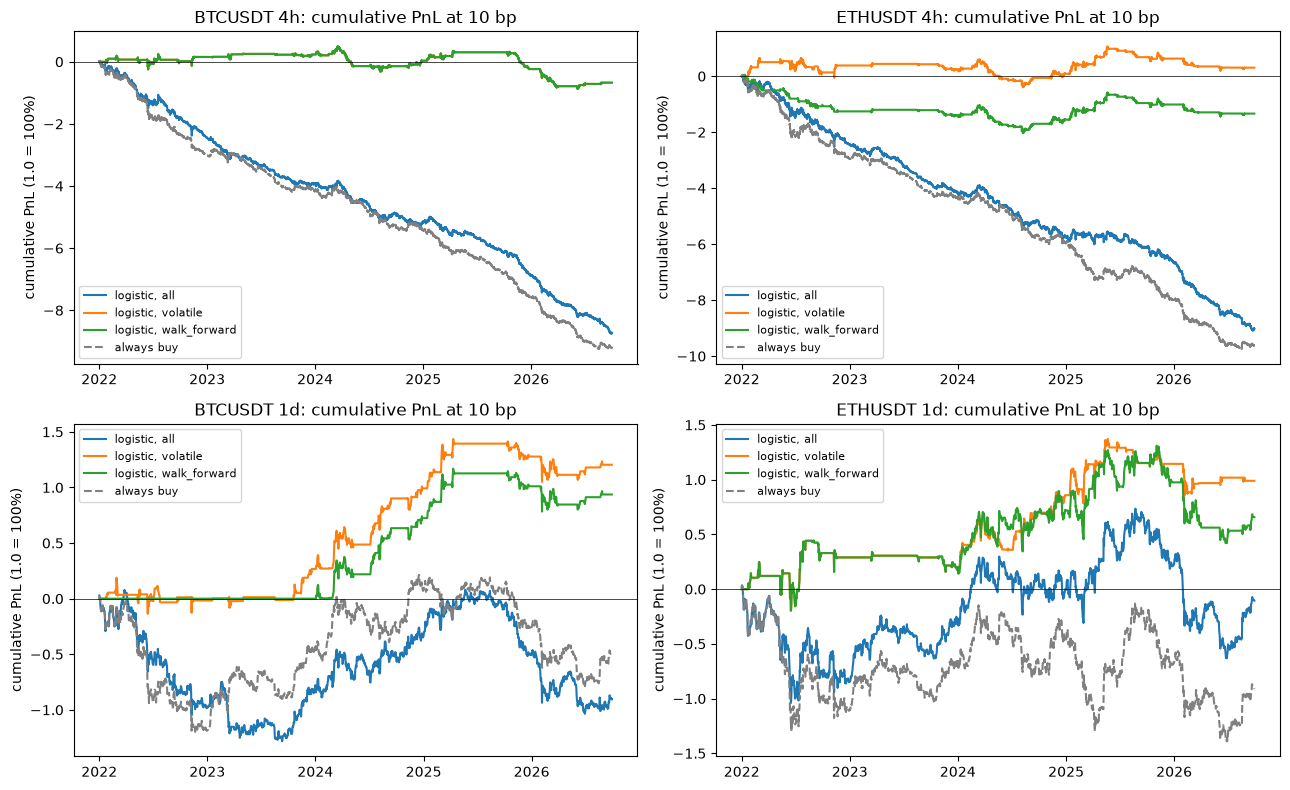

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for col, symbol in enumerate(SYMBOLS):
    for row, horizon in enumerate(["4h", "1d"]):
        ax = axes[row, col]
        df = decisions[(symbol, horizon, "logistic")]
        fwd_ret = df.loc[df.index >= test_start, "fwd_ret"]
        rules = strategies[(symbol, horizon, "logistic", COST)]
        for rule in RULES:
            pnl = butil.compute_pnl(rules[rule], fwd_ret, cost=COST)
            ax.plot(pnl.cumsum(), label=f"logistic, {rule}")
        buy = strategies[(symbol, horizon, "always_buy", COST)]["all"]
        pnl = butil.compute_pnl(buy, fwd_ret, cost=COST)
        ax.plot(pnl.cumsum(), color="gray", linestyle="--", label="always buy")
        ax.axhline(0, color="black", linewidth=0.5)
        ax.set_title(f"{symbol} {horizon}: cumulative PnL at 10 bp")
        ax.set_ylabel("cumulative PnL (1.0 = 100%)")
        ax.legend(fontsize=8)
plt.tight_layout()

## Year by year at 10 bp

Sum of the PnLs in each year for the logistic regression with the
`volatile` and `walk_forward` rules (0 when it does not trade).

In [11]:
rows = []
for symbol in SYMBOLS:
    for horizon in HORIZONS:
        df = decisions[(symbol, horizon, "logistic")]
        fwd_ret = df.loc[df.index >= test_start, "fwd_ret"]
        for rule in ["volatile", "walk_forward"]:
            pos = strategies[(symbol, horizon, "logistic", COST)][rule]
            pnl = butil.compute_pnl(pos, fwd_ret, cost=COST)
            by_year = pnl.groupby(pnl.index.year).sum()
            rows.append({"symbol": symbol, "horizon": horizon, "rule": rule})
            rows[-1].update(by_year.round(3).to_dict())
pd.DataFrame(rows).set_index(["symbol", "horizon", "rule"])

2022   2023   2024   2025   2026
symbol  horizon rule                                           
BTCUSDT 1h      volatile     -0.830 -1.161 -3.310 -2.622 -1.645
                walk_forward  0.000  0.000  0.000  0.000  0.000
        4h      volatile      0.156  0.078 -0.199 -0.270 -0.438
                walk_forward  0.156  0.078 -0.199 -0.270 -0.438
        1d      volatile     -0.016  0.284  0.724  0.286 -0.074
                walk_forward  0.000  0.000  0.724  0.286 -0.074
ETHUSDT 1h      volatile     -1.230 -1.115 -3.460 -3.563 -0.711
                walk_forward  0.000  0.000  0.000  0.000  0.000
        4h      volatile      0.383 -0.142 -0.154  0.541 -0.325
                walk_forward -1.257 -0.142 -0.154  0.541 -0.325
        1d      volatile      0.290 -0.113  0.682  0.286 -0.155
                walk_forward  0.290 -0.113  0.541  0.258 -0.318

## Observations

At 10 bp per round trip:
- Trading at every decision time loses money at every horizon on both
  coins, as in step 2
- Trading only in volatile markets does not help at 1h (-8.3 bp per trade
  on BTC, -7.8 bp on ETH) and about breaks even at 4h (-2.3 bp on BTC,
  +0.9 bp on ETH)
- At 1d it makes money on both coins: 25.4 bp per trade on BTC (475 trades,
  Sharpe 0.78, +120% in total over 2022-2026) and 18.4 bp on ETH (539
  trades, Sharpe 0.47, +99%)
- Always buying in volatile markets at 1d makes 12.3 bp on BTC and -3.2 bp
  on ETH, so the model adds about 13-22 bp per trade on top of the market
  move

Without hindsight (`walk_forward`):
- The rule picks volatile markets in most years at 4h and 1d (and normal
  markets too on ETH at 1d from 2024), and never trades at 1h
- At 1d it still makes money: 27.4 bp per trade on BTC (342 trades, Sharpe
  0.79; it starts only in 2024, when volatile markets had made money
  after costs in the earlier years) and 7.4 bp on ETH (884 trades, Sharpe
  0.26)
- At 4h it loses: -2.3 bp per trade on BTC and -4.2 bp on ETH. On ETH it
  traded normal markets in 2022, based on 2021 alone, and lost

Costs:
- 4h depends on the cost. At 5 bp, trading only in volatile markets makes
  2.7 bp per trade on BTC and 5.9 bp on ETH, and the walk-forward rule
  about the same on BTC (2.7 bp) and less on ETH (2.5 bp)
- 1d in volatile markets still makes money at 20 bp (15.4 bp per trade on
  BTC, 8.4 bp on ETH)

How sure:
- No result is 2 standard errors from zero: the best t-stat is 1.7 (BTC at
  1d), because there are only about 100 daily trades a year
- At 1d in volatile markets the yearly PnL is positive in 3 of 5 years on
  each coin, and negative in 2026 on both (January to September only), as
  the smaller edge in 2026 in step 3
- Drawdowns are large: the cumulative PnL fell by 39-52% of the position at
  1d in volatile markets, and by 89% on ETH with the walk-forward rule
- So trading only in volatile markets turns the 1d model from a small loss
  into a profit after realistic costs, also without hindsight on BTC. But
  it is about 100 trades a year with a t-stat under 2; it needs more data
  (other coins, earlier years) before it can be trusted